# Project Deliverable 1: Active Learning for Content Moderation

**Project:** Human-assisted content moderation (toxic comment detection) with the Civil Comments dataset

**Team:** Harish Shanmugam, Harshitha Kuppala

**Course:** Human-in-the-Loop Machine Learning, WiSe 26/27, HSBI

In this notebook we test whether active learning can reduce the number of comments moderators have to label.
We compare four ways of choosing which comments to label next: random, uncertainty, diversity and representative sampling.
The labels already in the dataset act as the annotator (simulated oracle).

Contents:
1. Setup and data
2. Experimental setup
3. Acquisition strategies
4. Active learning loop
5. Results
6. Discussion, limitations and conclusions

## 1. Setup and data

Imports. In Colab only the `datasets` package had to be installed, the rest is already available.

In [ ]:
!pip install -q datasets   # only needed on Colab
import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from sklearn.metrics import f1_score, accuracy_score, average_precision_score

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

### 1.1 Loading the data

We use the same sampling as in our baseline notebook: 25,000 comments from the train split, 5,000 from the test split, `seed=42`.
A comment counts as toxic if its `toxicity` score is at least 0.5. Empty comments are removed.

In [ ]:
from datasets import load_dataset

ds = load_dataset("google/civil_comments")

train_ds = ds["train"].train_test_split(train_size=25_000, seed=42)["train"]
val_ds   = ds["validation"].train_test_split(train_size=5_000, seed=42)["train"]
test_ds  = ds["test"].train_test_split(train_size=5_000, seed=42)["train"]

train_df = train_ds.to_pandas()
val_df   = val_ds.to_pandas()
test_df  = test_ds.to_pandas()

for df in [train_df, val_df, test_df]:
    df["label"] = (df["toxicity"] >= 0.5).astype(int)

# drop empty comments (cannot be represented)
train_df = train_df[train_df["text"].str.strip().str.len() > 0].reset_index(drop=True)
test_df  = test_df[test_df["text"].str.strip().str.len() > 0].reset_index(drop=True)

print("Pool (train):", len(train_df), "| Test:", len(test_df))
print("Toxic share in pool: %.2f%%" % (100 * train_df["label"].mean()))
print("Toxic share in test: %.2f%%" % (100 * test_df["label"].mean()))

README.md:   0%|          | 0.00/7.73k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  194MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  187MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

... (3 outputs left out)

Generating train split:   0%|          | 0/1804874 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/97320 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/97320 [00:00<?, ? examples/s]

Pool (train): 25000 | Test: 5000
Toxic share in pool: 8.04%
Toxic share in test: 7.82%


## 2. Experimental setup

| Component | Our choice | Why |
|---|---|---|
| Task | Binary classification, toxic vs. non-toxic | Same task as our baseline |
| Data | 25k training comments are the unlabeled pool, 5k test comments are only used for evaluation | Same split as the baseline, the test set is never used to select examples |
| Oracle | The existing dataset label is revealed when a comment is queried | Simulated annotation as in Labs 03-05 |
| Model | TF-IDF (1-2 grams, 20k features) + Logistic Regression with `class_weight="balanced"` | Our baseline model, fast enough to retrain in every round |
| Representation for diversity and representativeness | TF-IDF reduced to 100 dimensions with TruncatedSVD (LSA), normalised, cosine similarity | Distances in the sparse 20k-dim TF-IDF space are expensive and not very informative |
| Initial labeled set L0 | 100 random comments, different for each seed but the same for all strategies | We do not know the labels in advance, so we start randomly |
| Batch size and rounds | 50 comments per round, 20 rounds | Smaller batches keep the selection adaptive |
| Budget | 1,000 queried labels (1,100 labels in total with L0), about 4% of the pool | A small moderation budget |
| Repetitions | 5 seeds (0-4) | Required by the task, shows how much results vary |
| Main metric | Macro-F1 on the test set | Only about 8% of comments are toxic, so accuracy is misleading (a model that never predicts toxic already gets 92%) |
| Other metrics | F1 of the toxic class, average precision (PR-AUC), accuracy | The toxic class is what matters for moderation, PR-AUC does not depend on the 0.5 threshold |

To keep the comparison fair, within one seed all strategies use the same L0, pool, model, budget, batch size, test set and metric. Only the selection strategy changes.

The TF-IDF vocabulary and the LSA projection are fitted on the pool texts only (no labels, no test data). In pool-based active learning the unlabeled texts are available from the start, so this is not leakage.

In [ ]:
CONFIG = {
    "INITIAL_SIZE": 100,      # |L0|
    "BATCH_SIZE": 50,         # labels per AL round
    "N_ROUNDS": 20,           # acquisition rounds  -> budget = 50 * 20 = 1000
    "SEEDS": [0, 1, 2, 3, 4], # >= 5 repetitions
    "LSA_DIM": 100,           # embedding size for diversity/representativeness
    "KNN_DENSITY": 20,        # neighbours used for pool density
    "COMBINED_PREFILTER": 10, # combined strategy: keep 10 x batch most uncertain
}
CONFIG["BUDGET"] = CONFIG["BATCH_SIZE"] * CONFIG["N_ROUNDS"]
print(CONFIG)

{'INITIAL_SIZE': 100, 'BATCH_SIZE': 50, 'N_ROUNDS': 20, 'SEEDS': [0, 1, 2, 3, 4], 'LSA_DIM': 100, 'KNN_DENSITY': 20, 'COMBINED_PREFILTER': 10, 'BUDGET': 1000}


### 2.1 Representations

* `X_pool`, `X_test`: sparse TF-IDF features for the classifier (same settings as the baseline).
* `E_pool`: 100-dimensional LSA vectors of the pool, normalised so that the dot product is the cosine similarity. These are used by diversity and representative sampling.
* `pool_density`: for every pool comment, the mean similarity to its 20 nearest neighbours in the pool. High values mean the comment is in a dense, common region.

In [ ]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=20_000, sublinear_tf=True)
X_pool = vectorizer.fit_transform(train_df["text"])     # fit on pool text only
X_test = vectorizer.transform(test_df["text"])
y_pool = train_df["label"].to_numpy()                   # hidden "oracle" labels
y_test = test_df["label"].to_numpy()

svd = TruncatedSVD(n_components=CONFIG["LSA_DIM"], random_state=42)
E_pool = normalize(svd.fit_transform(X_pool)).astype(np.float32)

# Pool density: mean cosine similarity to the k nearest neighbours in the pool (static, computed once)
nn = NearestNeighbors(n_neighbors=CONFIG["KNN_DENSITY"] + 1, metric="cosine").fit(E_pool)
dist, _ = nn.kneighbors(E_pool)
pool_density = (1 - dist[:, 1:]).mean(axis=1)           # skip the point itself

print("X_pool:", X_pool.shape, "| E_pool:", E_pool.shape)
print("Explained variance of LSA: %.1f%%" % (100 * svd.explained_variance_ratio_.sum()))

X_pool: (25000, 20000) | E_pool: (25000, 100)
Explained variance of LSA: 10.2%


## 3. Acquisition strategies

Each strategy gets the current model, the unlabeled indices and the labeled indices, and returns `k` comments to label.

**Random sampling (baseline).** Picks `k` unlabeled comments at random.

**Uncertainty sampling (least confidence).** Scores every comment with $1 - \max_y P(y \mid x)$ and takes the top `k`.
In a binary task the most uncertain comments are the ones with $P(\text{toxic})$ near 0.5.
With two classes, least confidence, margin, ratio and entropy all give the same ranking (they all depend only on $|p - 0.5|$), so we only use one of them.

**Diversity sampling (greedy k-center).** Based on Lecture 04 and Sener & Savarese (2018). In every step we pick the comment that is farthest away from its closest labeled or already selected comment (cosine distance in LSA space). This should spread the batch over the data space and avoid near-duplicates.

**Representative sampling (relative density).** Based on the relative representative sampling idea from Lecture 04 and information density in Settles (2009, section 3.6). We want comments that are common in the pool but not yet covered by the labeled data:

$$a(x) = \text{density}_U(x) - \max_{x' \in L \cup Q} \cos(x, x')$$

The first term is the mean similarity to the 20 nearest pool neighbours, the second term is how close the comment already is to something labeled or selected. We build the batch one comment at a time and update the second term after each pick, so the batch does not fill up with copies of the same comment.

**Combined: uncertainty, then clustering (extra).** The two-stage policy from Lecture 05. We keep the 500 most uncertain comments, cluster them into `k` groups with k-means and take the comment closest to each centroid. This is an additional experiment and not one of the required strategies.

In [ ]:
def chunked_max_sim(E_a, E_b, chunk=4096):
    # max cosine similarity of each row of E_a to any row of E_b
    out = np.empty(len(E_a), dtype=np.float32)
    for s in range(0, len(E_a), chunk):
        out[s:s + chunk] = (E_a[s:s + chunk] @ E_b.T).max(axis=1)
    return out


def select_random(model, unl, lab, k, rng):
    return rng.choice(unl, size=k, replace=False)


def select_uncertainty(model, unl, lab, k, rng):
    p = model.predict_proba(X_pool[unl])[:, 1]
    score = 1 - np.maximum(p, 1 - p)              # least confidence
    return unl[np.argsort(-score, kind="stable")[:k]]


def select_diversity(model, unl, lab, k, rng):
    # greedy k-center: maximise distance to nearest labeled / selected point
    E_unl = E_pool[unl]
    min_dist = 1 - chunked_max_sim(E_unl, E_pool[lab])
    chosen = []
    for _ in range(k):
        j = int(np.argmax(min_dist))
        chosen.append(j)
        min_dist = np.minimum(min_dist, 1 - E_unl @ E_unl[j])
        min_dist[j] = -np.inf
    return unl[np.array(chosen)]


def select_representative(model, unl, lab, k, rng):
    # relative density: dense in the pool, but not yet covered by the labeled set
    E_unl = E_pool[unl]
    covered = chunked_max_sim(E_unl, E_pool[lab])
    dens = pool_density[unl]
    chosen = []
    for _ in range(k):
        score = dens - covered
        score[chosen] = -np.inf
        j = int(np.argmax(score))
        chosen.append(j)
        covered = np.maximum(covered, E_unl @ E_unl[j])
    return unl[np.array(chosen)]


def select_uncertainty_diversity(model, unl, lab, k, rng):
    m = min(len(unl), CONFIG["COMBINED_PREFILTER"] * k)
    cand = select_uncertainty(model, unl, lab, m, rng)
    E_c = E_pool[cand]
    km = KMeans(n_clusters=k, n_init=3, random_state=int(rng.integers(1_000_000))).fit(E_c)
    chosen = []
    for c in range(k):
        members = np.where(km.labels_ == c)[0]
        if len(members) == 0:
            continue
        d = ((E_c[members] - km.cluster_centers_[c]) ** 2).sum(axis=1)
        chosen.append(cand[members[np.argmin(d)]])
    chosen = list(dict.fromkeys(chosen))
    if len(chosen) < k:                           # top up if some clusters were empty
        rest = [i for i in cand if i not in set(chosen)]
        chosen += rest[: k - len(chosen)]
    return np.array(chosen)


STRATEGIES = {
    "Random": select_random,
    "Uncertainty (least confidence)": select_uncertainty,
    "Diversity (k-center greedy)": select_diversity,
    "Representative (relative density)": select_representative,
    "Combined (uncertainty → clusters)": select_uncertainty_diversity,   # extra
}
REQUIRED = list(STRATEGIES)[:4]

## 4. Active learning loop

For every seed:
1. Draw 100 random comments as L0 (shared by all strategies). If L0 only contains one class we draw again. In practice moderators would simply keep labeling random comments until a toxic one shows up.
2. For each strategy, repeat 20 times: train the model, evaluate on the test set, select 50 comments, reveal their labels, and move them from the pool to the labeled set.
3. After the last batch the model is trained and evaluated once more, so every curve has 21 points (100 to 1,100 labels).

We also store how many toxic comments each strategy has collected, since this matters a lot with imbalanced data.
The results are saved to `results/al_results.csv`. With `RUN_EXPERIMENTS = False` the plots can be recreated without running everything again.

In [ ]:
def train_model(X, y, seed):
    model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=seed)
    return model.fit(X, y)


def evaluate(model):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {
        "macro_f1": f1_score(y_test, pred, average="macro"),
        "f1_toxic": f1_score(y_test, pred, pos_label=1),
        "pr_auc": average_precision_score(y_test, proba),
        "accuracy": accuracy_score(y_test, pred),
    }


def initial_set(seed):
    rng = np.random.default_rng(10_000 + seed)
    while True:
        L0 = rng.choice(len(y_pool), size=CONFIG["INITIAL_SIZE"], replace=False)
        if len(np.unique(y_pool[L0])) == 2:
            return L0


def run_al(strategy_name, seed):
    select = STRATEGIES[strategy_name]
    rng = np.random.default_rng(seed)
    labeled = initial_set(seed)
    is_lab = np.zeros(len(y_pool), dtype=bool); is_lab[labeled] = True
    rows = []
    for rnd in range(CONFIG["N_ROUNDS"] + 1):
        model = train_model(X_pool[labeled], y_pool[labeled], seed)   # oracle labels of L only
        rows.append({"strategy": strategy_name, "seed": seed, "round": rnd,
                     "n_labeled": len(labeled), "n_toxic_labeled": int(y_pool[labeled].sum()),
                     **evaluate(model)})
        if rnd == CONFIG["N_ROUNDS"]:
            break
        unl = np.where(~is_lab)[0]
        query = select(model, unl, labeled, CONFIG["BATCH_SIZE"], rng)
        assert len(set(query)) == CONFIG["BATCH_SIZE"] and not is_lab[query].any()
        is_lab[query] = True                                           # oracle reveals labels
        labeled = np.concatenate([labeled, query])
    return rows

In [ ]:
RUN_EXPERIMENTS = True          # set to False to only reload saved results
RESULTS_CSV = os.path.join(RESULTS_DIR, "al_results.csv")

if RUN_EXPERIMENTS:
    all_rows = []
    t0 = time.time()
    for seed in CONFIG["SEEDS"]:
        for name in STRATEGIES:
            t = time.time()
            all_rows += run_al(name, seed)
            print(f"seed {seed} | {name:36s} | final macro-F1 {all_rows[-1]['macro_f1']:.3f} | {time.time()-t:5.1f}s")
    results = pd.DataFrame(all_rows)
    results.to_csv(RESULTS_CSV, index=False)
    print(f"Total time: {(time.time()-t0)/60:.1f} min")
else:
    results = pd.read_csv(RESULTS_CSV)

results.head()

seed 0 | Random                               | final macro-F1 0.524 |   3.5s
seed 0 | Uncertainty (least confidence)       | final macro-F1 0.675 |   6.8s
seed 0 | Diversity (k-center greedy)          | final macro-F1 0.520 |   6.7s
seed 0 | Representative (relative density)    | final macro-F1 0.535 |   8.8s
seed 0 | Combined (uncertainty → clusters)    | final macro-F1 0.640 |   6.3s
seed 1 | Random                               | final macro-F1 0.519 |   6.2s
seed 1 | Uncertainty (least confidence)       | final macro-F1 0.652 |   5.7s
seed 1 | Diversity (k-center greedy)          | final macro-F1 0.509 |   8.0s
seed 1 | Representative (relative density)    | final macro-F1 0.501 |   6.3s
seed 1 | Combined (uncertainty → clusters)    | final macro-F1 0.635 |   8.1s
seed 2 | Random                               | final macro-F1 0.485 |   3.1s
seed 2 | Uncertainty (least confidence)       | final macro-F1 0.650 |   4.6s
seed 2 | Diversity (k-center greedy)          | final macro-F1 0

,strategy,seed,round,n_labeled,n_toxic_labeled,macro_f1,f1_toxic,pr_auc,accuracy
0,Random,0,0,100,9,0.484709,0.010127,0.157736,0.9218
1,Random,0,1,150,15,0.484709,0.010127,0.158880,0.9218
2,Random,0,2,200,19,0.487272,0.015152,0.154258,0.9220
3,Random,0,3,250,21,0.487198,0.015113,0.150523,0.9218
4,Random,0,4,300,24,0.489742,0.020101,0.161867,0.9220


### 4.1 Reference: model trained on the whole pool

As an upper reference we train the same model on all 25k pool comments, which is what we would get if everything was labeled.

In [ ]:
full_model = train_model(X_pool, y_pool, 42)
full_scores = evaluate(full_model)
print({k: round(v, 4) for k, v in full_scores.items()})

{'macro_f1': 0.7052, 'f1_toxic': 0.4661, 'pr_auc': np.float64(0.4954), 'accuracy': 0.8992}


## 5. Results

### 5.1 Learning curves

The lines show the mean over the 5 seeds, the shaded area is plus/minus one standard deviation. The dotted line is the model trained on the full pool.

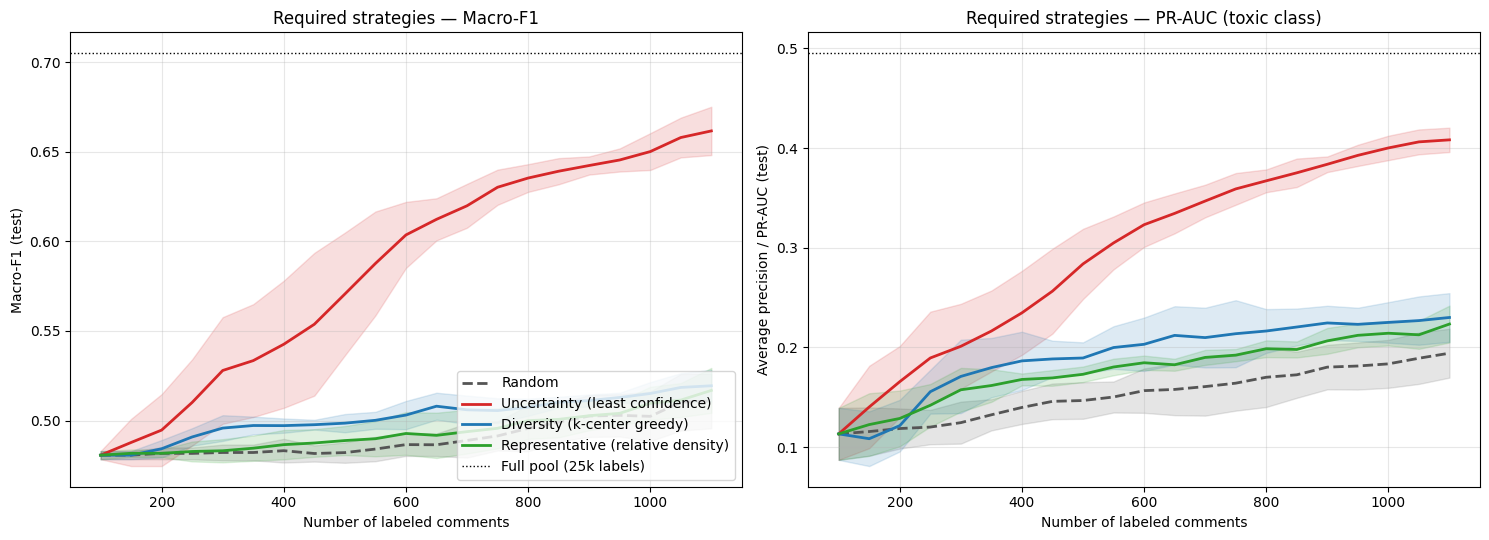

In [ ]:
COLORS = {
    "Random": "#555555",
    "Uncertainty (least confidence)": "#d62728",
    "Diversity (k-center greedy)": "#1f77b4",
    "Representative (relative density)": "#2ca02c",
    "Combined (uncertainty → clusters)": "#9467bd",
}

def plot_curves(metric, ylabel, strategies, ax, full=None):
    for name in strategies:
        g = results[results.strategy == name].groupby("n_labeled")[metric]
        m, s = g.mean(), g.std()
        ls = "--" if name == "Random" else "-"
        ax.plot(m.index, m.values, ls, color=COLORS[name], label=name, lw=2)
        ax.fill_between(m.index, m - s, m + s, color=COLORS[name], alpha=0.15)
    if full is not None:
        ax.axhline(full, color="black", lw=1, ls=":", label="Full pool (25k labels)")
    ax.set_xlabel("Number of labeled comments")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
plot_curves("macro_f1", "Macro-F1 (test)", REQUIRED, axes[0], full_scores["macro_f1"])
axes[0].set_title("Required strategies — Macro-F1")
plot_curves("pr_auc", "Average precision / PR-AUC (test)", REQUIRED, axes[1], full_scores["pr_auc"])
axes[1].set_title("Required strategies — PR-AUC (toxic class)")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "learning_curves_required.png"), dpi=150)
plt.show()

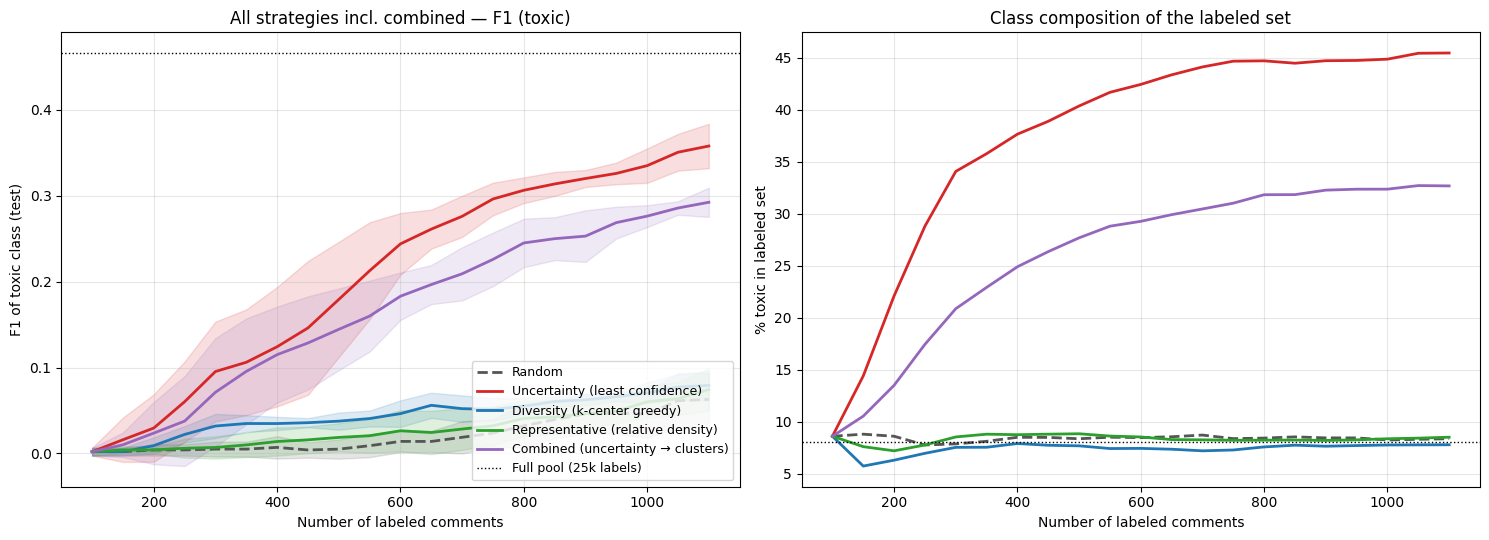

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
plot_curves("f1_toxic", "F1 of toxic class (test)", list(STRATEGIES), axes[0], full_scores["f1_toxic"])
axes[0].set_title("All strategies incl. combined — F1 (toxic)")
axes[0].legend(loc="lower right", fontsize=9)

# share of toxic comments the strategy has collected
for name in STRATEGIES:
    r = results[results.strategy == name].copy()
    r["toxic_share"] = r.n_toxic_labeled / r.n_labeled
    g = r.groupby("n_labeled")["toxic_share"]
    axes[1].plot(g.mean().index, 100 * g.mean().values, color=COLORS[name], lw=2,
                 ls="--" if name == "Random" else "-", label=name)
axes[1].axhline(100 * y_pool.mean(), color="black", lw=1, ls=":", label="Toxic share in pool")
axes[1].set_xlabel("Number of labeled comments"); axes[1].set_ylabel("% toxic in labeled set")
axes[1].set_title("Class composition of the labeled set"); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "learning_curves_extra.png"), dpi=150)
plt.show()

**What we see in the curves**

* All strategies start at the same point (macro-F1 about 0.48 with 100 labels), because they share L0.
* Uncertainty sampling separates from the others after about 300 labels and keeps improving until the end of the budget. At 1,100 labels it reaches a macro-F1 of 0.662, while random is at 0.511. The shaded bands do not overlap after about 400 labels.
* Random, diversity and representative sampling stay close together in macro-F1. Random sampling hardly improves at all: after 1,100 labels its F1 for the toxic class is only 0.06, so the model almost never predicts "toxic" at the 0.5 threshold.
* In PR-AUC (right plot) the picture is a bit different. Diversity and representative sampling end slightly above random (0.230 and 0.223 vs. 0.194), so their models rank toxic comments a little better, even though this does not show up at the 0.5 threshold.
* The class composition plot explains most of this. Uncertainty sampling ends up with 45% toxic comments in its labeled set and the combined strategy with 33%. Random, diversity and representative stay at the pool rate of about 8%, which means only around 90 toxic examples after 1,100 labels.
* The combined strategy is clearly better than random but below pure uncertainty sampling (toxic-class F1 0.29 vs. 0.36).

### 5.2 Summary table

* **Final**: score after the whole budget (1,100 labels), mean and standard deviation over the seeds.
* **AULC**: area under the learning curve divided by its width, so the average score over the whole budget and not only at the end.
* **Wins vs random**: in how many of the 5 seeds the AULC of the strategy is higher than random's AULC in the same seed.
* **Labels to 90% of full**: first point where the mean curve reaches 90% of the full-pool macro-F1 (a dash means it was not reached within the budget).

In [ ]:
def aulc(df, metric):
    d = df.sort_values("n_labeled")
    x, y = d.n_labeled.to_numpy(), d[metric].to_numpy()
    trap = getattr(np, "trapezoid", None) or np.trapz   # works on old and new numpy
    return trap(y, x) / (x[-1] - x[0])

target = 0.9 * full_scores["macro_f1"]
rows = []
aulc_tab = results.groupby(["strategy", "seed"]).apply(lambda d: aulc(d, "macro_f1"), include_groups=False).unstack("seed")
for name in STRATEGIES:
    r = results[results.strategy == name]
    final = r[r["round"] == CONFIG["N_ROUNDS"]]
    mean_curve = r.groupby("n_labeled")["macro_f1"].mean()
    reached = mean_curve[mean_curve >= target]
    rows.append({
        "Strategy": name,
        "Final macro-F1": f"{final.macro_f1.mean():.3f} ± {final.macro_f1.std():.3f}",
        "Final F1 toxic": f"{final.f1_toxic.mean():.3f} ± {final.f1_toxic.std():.3f}",
        "Final PR-AUC": f"{final.pr_auc.mean():.3f} ± {final.pr_auc.std():.3f}",
        "AULC macro-F1": f"{aulc_tab.loc[name].mean():.3f} ± {aulc_tab.loc[name].std():.3f}",
        "Wins vs random (AULC)": "—" if name == "Random" else f"{int((aulc_tab.loc[name] > aulc_tab.loc['Random']).sum())}/{len(CONFIG['SEEDS'])}",
        "Labels to 90% of full": int(reached.index[0]) if len(reached) else "—",
        "% toxic collected": f"{100 * (final.n_toxic_labeled / final.n_labeled).mean():.1f}%",
    })
summary = pd.DataFrame(rows).set_index("Strategy")
summary.to_csv(os.path.join(RESULTS_DIR, "summary.csv"))
print(f"Full-pool macro-F1 = {full_scores['macro_f1']:.3f}  ->  target (90%) = {target:.3f}")
summary

Full-pool macro-F1 = 0.705  ->  target (90%) = 0.635


,Final macro-F1,Final F1 toxic,Final PR-AUC,AULC macro-F1,Wins vs random (AULC),Labels to 90% of full,% toxic collected
Strategy,,,,,,,
Random,0.511 ± 0.015,0.063 ± 0.031,0.194 ± 0.025,0.490 ± 0.006,—,—,8.4%
Uncertainty (least confidence),0.662 ± 0.013,0.358 ± 0.026,0.408 ± 0.012,0.586 ± 0.015,5/5,800,45.5%
Diversity (k-center greedy),0.519 ± 0.009,0.079 ± 0.017,0.230 ± 0.024,0.502 ± 0.004,5/5,—,7.8%
Representative (relative density),0.517 ± 0.013,0.074 ± 0.025,0.223 ± 0.018,0.493 ± 0.008,4/5,—,8.5%
Combined (uncertainty → clusters),0.628 ± 0.009,0.292 ± 0.017,0.392 ± 0.013,0.564 ± 0.015,5/5,—,32.7%


In [ ]:
# Difference to random at selected budgets (mean over seeds of the paired difference)
budgets = [200, 400, 600, 800, 1100]
piv = results.pivot_table(index=["seed", "n_labeled"], columns="strategy", values="macro_f1")
diff = piv.sub(piv["Random"], axis=0).drop(columns="Random")
diff_mean = diff.groupby("n_labeled").mean().loc[budgets]
diff_std = diff.groupby("n_labeled").std().loc[budgets]
print("Macro-F1 difference to random (mean over 5 seeds; positive = better than random)")
(diff_mean.round(3).astype(str) + " ± " + diff_std.round(3).astype(str)).T

Macro-F1 difference to random (mean over 5 seeds; positive = better than random)


n_labeled,200,400,600,800,1100
strategy,,,,,
Combined (uncertainty → clusters),0.01 ± 0.015,0.055 ± 0.024,0.086 ± 0.013,0.108 ± 0.017,0.117 ± 0.011
Diversity (k-center greedy),0.003 ± 0.003,0.014 ± 0.007,0.016 ± 0.012,0.012 ± 0.016,0.008 ± 0.017
Representative (relative density),0.0 ± 0.002,0.003 ± 0.005,0.006 ± 0.012,0.004 ± 0.016,0.006 ± 0.017
Uncertainty (least confidence),0.013 ± 0.017,0.059 ± 0.034,0.117 ± 0.015,0.14 ± 0.008,0.151 ± 0.014


**What the tables show**

* Uncertainty sampling is the only strategy that reaches 90% of the full-pool macro-F1 (0.635). It gets there with 800 labels, which is about 3% of the pool. At 1,100 labels it is at 94% of the full-pool score (0.662 vs. 0.705). Random sampling does not get close within the budget.
* The advantage of uncertainty sampling over random grows during the experiment: +0.013 at 200 labels (smaller than the standard deviation, so not reliable yet), +0.059 at 400, +0.117 at 600 and +0.151 at 1,100. It wins in 5 out of 5 seeds.
* Diversity also wins against random in 5/5 seeds by AULC, but the difference is very small (0.502 vs. 0.490) and at 1,100 labels it is +0.008 ± 0.017, so within the seed-to-seed variation. We do not see this as a real improvement in macro-F1.
* Representative sampling is practically the same as random (AULC 0.493 vs. 0.490, 4/5 wins).

### 5.3 What do the strategies select?

A short look at the first batch each strategy selects for seed 0: share of toxic comments, comment length and how similar the comments in one batch are to each other.

In [ ]:
seed = 0
L0 = initial_set(seed)
m0 = train_model(X_pool[L0], y_pool[L0], seed)
unl0 = np.setdiff1d(np.arange(len(y_pool)), L0)
rows = []
for name, fn in STRATEGIES.items():
    q = fn(m0, unl0, L0, CONFIG["BATCH_SIZE"], np.random.default_rng(seed))
    texts = train_df.loc[q, "text"]
    sims = E_pool[q] @ E_pool[q].T
    np.fill_diagonal(sims, 0)
    rows.append({"Strategy": name,
                 "% toxic in batch": 100 * y_pool[q].mean(),
                 "median length (chars)": texts.str.len().median(),
                 "mean within-batch similarity": sims.sum() / (len(q) * (len(q) - 1)),
                 "example": texts.iloc[0][:120].replace("\n", " ")})
pd.set_option("display.max_colwidth", 130)
pd.DataFrame(rows).set_index("Strategy").round(3)

,% toxic in batch,median length (chars),mean within-batch similarity,example
Strategy,,,,
Random,12.0,139.5,0.136,Great idea... this will help setup the industry.
Uncertainty (least confidence),38.0,39.5,0.163,You're a troll.
Diversity (k-center greedy),0.0,11.5,0.000,Camoufflage russe. -)
Representative (relative density),6.0,22.5,0.011,"Thank you, Mayor Berkowitz."
Combined (uncertainty → clusters),24.0,85.0,0.126,Won't someone PLEASE think of the rich pampered old white men? They just never seem to get a break.


**Observations**

* Diversity sampling picks very short and unusual comments (median 11.5 characters, e.g. "Camoufflage russe. -)") and none of them are toxic. In the LSA space these comments are far away from everything else, but that does not make them useful to label. This matches the warning from Lecture 04 that "different" is not the same as "informative".
* Representative sampling picks short, generic comments like "Thank you, Mayor Berkowitz.", which are common in the pool but easy for the model.
* Uncertainty sampling picks short comments with insults or strong wording ("You're a troll."), 38% of them toxic. Its batch has the highest within-batch similarity (0.163), so there is some redundancy, but it did not stop the strategy from performing best.
* The combined strategy picks longer comments and fewer toxic ones (24%) than pure uncertainty sampling. Choosing the comment closest to each cluster centre seems to favour more "typical" comments, which are less close to the decision boundary. This could explain why it is below uncertainty sampling.

## 6. Discussion

**Which strategies work better, and do they beat random?**
Uncertainty sampling is clearly the best strategy in our setup. It beats random in all 5 seeds, the gap grows with the budget, and it reaches 90% of the full-pool macro-F1 with 800 labels, which random sampling does not reach at all within 1,100 labels.
Diversity and representative sampling do not give a meaningful improvement over random in macro-F1. They help a bit in PR-AUC, but the difference is small.
The combined strategy is much better than random but worse than pure uncertainty sampling, so for our data adding cluster diversity on top of uncertainty did not help.

**Why?**
The main reason seems to be class imbalance. With only 8% toxic comments, random sampling gives the model very few toxic examples, and even with balanced class weights the model rarely predicts the toxic class.
Uncertainty sampling picks comments close to the decision boundary, and many of those are toxic, so it automatically collects a much more balanced training set (45% toxic).
Diversity and representative sampling do not use the model at all, so they collect toxic comments at the same rate as random. In addition, our LSA space only explains about 10% of the TF-IDF variance, so the distances used by these strategies are quite rough. The farthest points in this space are mostly very short or strange comments, not the cases the model struggles with.

**What does this mean for our project?**
Active learning, specifically uncertainty sampling, looks useful for content moderation. In our simulation it reaches a macro-F1 that random sampling does not reach with the same budget, so moderators could spend fewer labels for the same model quality.
This also fits our baseline analysis, where most errors were in the uncertain probability range (0.3-0.7). Uncertainty sampling sends exactly these comments to humans.
For the next deliverables we plan to continue with uncertainty sampling as our acquisition strategy.

## 7. Limitations

* **Simulated oracle.** The labels are averaged crowd ratings with a 0.5 threshold. Real moderators often disagree on borderline comments, and these are exactly the comments that uncertainty sampling selects. We also assume every comment takes the same time to label (Lecture 05: fewer labels does not automatically mean less time).
* **Ambiguous comments.** Comments with a toxicity score near 0.5 may be ambiguous no matter how many labels we collect, so some uncertainty queries may not add much information.
* **Fixed threshold.** All F1 scores use a 0.5 threshold. The random-sampling model hardly ever crosses it, while PR-AUC shows that its ranking does improve. Tuning the threshold on the validation set might reduce the gap between the strategies in macro-F1.
* **One model and one representation.** All results are for TF-IDF + Logistic Regression. Diversity and representative sampling depend strongly on the representation, and with sentence embeddings they might work better.
* **Fixed settings.** We only tried one batch size (50), one budget (1,000), one L0 size (100) and did not tune the model during the loop.
* **Data.** The pool and test set are samples from Civil Comments and come from the same distribution. Real comments on a platform can change over time. The test set has about 390 toxic comments, so toxic-class scores are somewhat noisy.
* **Five repetitions.** Five seeds give a first idea of the variation. We did not run a formal significance test.

## 8. Conclusions

In our simulated experiment, uncertainty sampling clearly outperforms random sampling for toxic comment detection. It reaches 94% of the full-pool macro-F1 with only about 4% of the labels, mainly because it finds many more toxic comments for the model to learn from.
Diversity and representative sampling, using our LSA representation, perform about the same as random. Combining uncertainty with clustering did not improve on uncertainty sampling alone.
Next we want to check whether a better text representation (sentence embeddings) changes the result for the coverage-based strategies, and look at the uncertain comments from the annotation side: how hard they are to label and how much annotators agree on them.

## References
- Lecture slides VL03-VL05 and Labs 03-05, Human-in-the-Loop ML, WiSe 26/27, HSBI.
- Settles, B. (2009). Active Learning Literature Survey. Technical Report 1648, University of Wisconsin-Madison.
- Sener, O., & Savarese, S. (2018). Active Learning for Convolutional Neural Networks: A Core-Set Approach. ICLR.
- Munro, R. (2021). Human-in-the-Loop Machine Learning. Manning, chapters 3-5.
- Borkan, D., Dixon, L., Sorensen, J., Thain, N., & Vasserman, L. (2019). Nuanced Metrics for Measuring Unintended Bias with Real Data for Text Classification. WWW Companion.